
# 01: Model description

What evoparam does, shown on one example curve.


## Introduction

When the brain receives a short stimulus (a flash of light, a sound, a tiny electrical
pulse), the electrodes that record its activity show a small wave just after it. This
wave is called an **evoked response**.

One response is hidden in the noise, so the stimulus is repeated many times and the
recordings are averaged. What is left is one clean curve: time on the x-axis, voltage on
the y-axis.

evoparam describes this curve with a few numbers. It looks for the **bumps** in it: when
each bump happens, how high it is, and how wide it is.

In this first tutorial, we make an example curve, let evoparam describe it, and look at
what the description means.



In [1]:
# Import what we need
from evoparam import (
    fit_response,
    gen_response,
    plot_annotated_fit,
    plot_fit,
    plot_response,
    report,
)

## Making an example curve

To learn, it helps to start from a curve whose answer we already know.
``gen_response`` makes one. Each bump is given by three numbers:

- **latency**: when the bump peaks, in milliseconds (ms) after the stimulus;
- **amplitude**: how high it is, in microvolts (µV); negative means it goes down;
- **width**: how wide it is, in ms, measured at half its height.

Here we ask for two bumps that both go down: a sharp one at 25 ms and a broad one at
150 ms.



In [2]:
# Make an example curve with two bumps: [latency (ms), amplitude (µV), width (ms)]
times, signal = gen_response([[25, -150, 10], [150, -80, 80]], seed=3)

``seed=3`` fixes the random noise, so that you get the same curve each time you run this
page.

Let's look at the curve. The stimulus happens at time 0 (the dashed line).



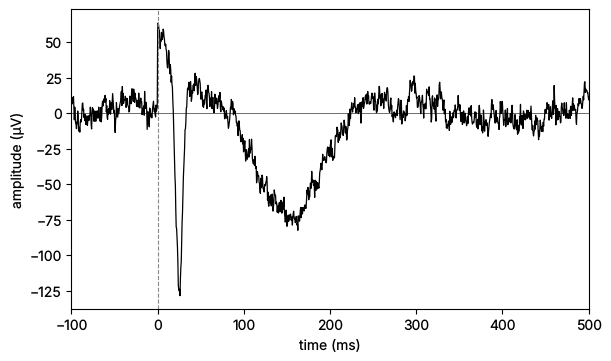

In [3]:
# Plot the curve, from 100 ms before to 500 ms after the stimulus
fig = plot_response(times, signal, xlim=[-100, 500], color="black")

Before 0, the curve only wiggles: that is noise. Just after 0 it jumps up and slowly comes
back, then the two bumps go down, one sharp and one broad.



## Describing the curve

Now we ask evoparam to describe it. ``report`` does everything in one line: it fits the
model, shows a summary and draws a figure.

``"ccep"`` is a **preset**: a ready-made set of settings, here the one for responses to
electrical pulses.



                    evoparam - RESPONSE MODEL

                     fit window: 9 to 500 ms
          background: exponential, time constant 35.4 ms

                      2 component(s) found:
            label        latency     amplitude     width
            N1           25.0 ms    -152.1 µV     9.5 ms
            N2          151.9 ms     -77.4 µV    79.2 ms

           fit quality: R2 = 0.94, noise level = 7.4 µV
  (latency: time of the peak; width: full width at half maximum)


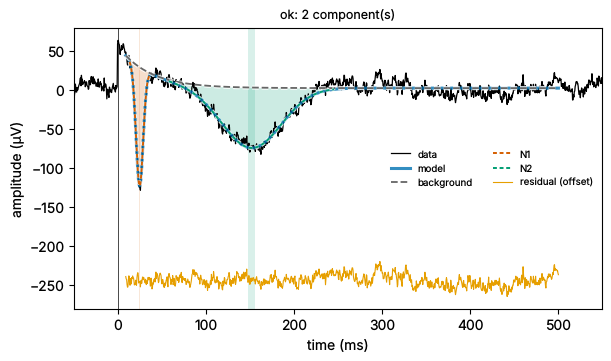

In [4]:
# Fit the model and draw the figure
fit = report(times, signal, preset="ccep")

# Show the summary
print(fit)

evoparam found the two bumps we put in, with the right timing, height and width. It
named them **N1** and **N2**: N for a bump that goes down, then a number in order of time.

In the figure, the black line is our curve and the thick blue line is the model. The grey
dashed line is the background. Each coloured area is one bump: it fills the space between
the background and the curve. The orange line at the bottom is what is left over.

The colour of the areas can be changed, for example ``plot_fit(fit, shade_color="grey")``,
or they can be turned off with ``shade=False``.



## Reading the numbers on the curve

``plot_annotated_fit`` draws each number where it is read on the curve:

- the **dot** is the peak of the bump;
- the **arrow** goes from the background to the peak: its length is the amplitude;
- the **dotted line** down to the time axis gives the latency;
- the **bar** across the bump, at half its height, is the width.



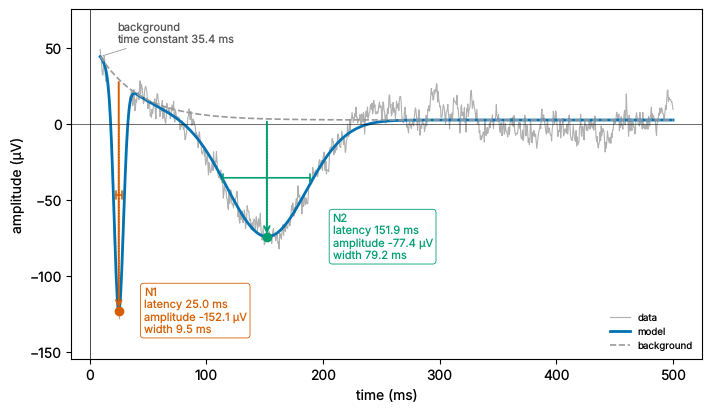

In [5]:
# Draw the model with its numbers
fig = plot_annotated_fit(fit)

## Conceptual overview

evoparam sees every curve as the sum of three parts.

**The background.** A slow change that is not a bump. Here it is the jump right after the
pulse that slowly fades away: the recording equipment recovering from the pulse. If it
were not removed, it would look like an extra bump or change the size of the real ones.

**The bumps.** Each bump has a simple shape (a bell curve) and is described by its
latency, amplitude and width. These numbers are usually what we want to measure.

**The noise.** Whatever is left: small random wiggles. evoparam measures how big they are
from the part of the curve before the stimulus, where there is nothing but noise.

<div class="alert alert-info"><h4>Note</h4>

evoparam decides on its own how many bumps there are. It adds them one at a time and
keeps a new bump only if it explains the curve clearly better than without it. This is
why it does not invent a bump in every small wiggle of the noise.

</div>



## Mathematical description

Written as a formula, the model is

\begin{align}y(t) = b(t) + \sum_{k=1}^{K} A_k \, s_k(t) + \varepsilon(t)\end{align}

- $y(t)$ is the curve, the voltage at time $t$.
- $b(t)$ is the background.
- $s_k(t)$ is the shape of bump number $k$: a bell curve with a height of 1,
  centred on its latency and as wide as its width.
- $A_k$ is the amplitude of bump $k$, which scales its shape to its real
  height.
- $K$ is the number of bumps, and $\sum$ means "add them all up".
- $\varepsilon(t)$ is the noise.

Fitting the model means finding the numbers that make the sum of the parts as close as
possible to the curve.



## Trying another curve

The same lines work on any curve. This one has an earlier, smaller first bump, a later
second bump and a stronger background.

This time we do the steps one by one: ``fit_response`` only fits the model (no figure),
``print`` shows the summary and ``plot_fit`` draws the result. ``report`` is these three
steps in one line.



In [6]:
# Two other bumps, and a background given as [height (µV), how fast it fades (ms)]
bumps = [[20, -100, 8], [200, -50, 100]]
times2, signal2 = gen_response(bumps, background=[80, 40], seed=1)

# Fit the model, without drawing
fit2 = fit_response(times2, signal2, preset="ccep")

                    evoparam - RESPONSE MODEL

                     fit window: 9 to 500 ms
          background: exponential, time constant 40.0 ms

                      2 component(s) found:
            label        latency     amplitude     width
            N1           20.0 ms     -92.2 µV     8.3 ms
            N2          201.3 ms     -59.0 µV    98.8 ms

           fit quality: R2 = 0.92, noise level = 7.1 µV
  (latency: time of the peak; width: full width at half maximum)


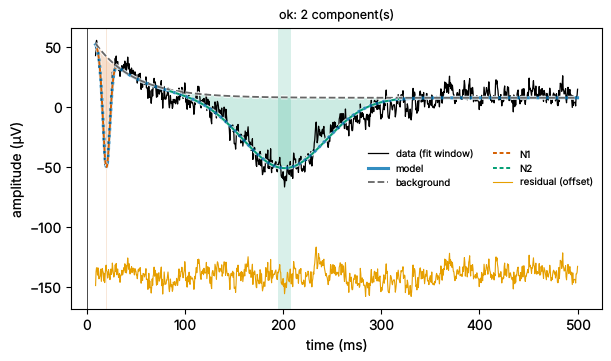

In [7]:
# Show the summary, then draw the fit
print(fit2)
fig = plot_fit(fit2)

<div class="alert alert-info"><h4>Note</h4>

Try it yourself: change the numbers given to ``gen_response`` (move a bump, make it
smaller, add more noise with ``noise=20``) and fit it again. When the bumps get
small compared to the noise, evoparam starts to miss them, as anyone would.

</div>



## Conclusion

evoparam describes a curve as a background, a few bumps and some noise, and gives the
timing, height and width of each bump. In the next tutorials, we look at the settings of
the model and use it on real recordings.

